# 11 - Final Evaluation on the Held-Out Test Set (BijliCast)

**CT-378 lifecycle, steps 6 and 7**

The test split is used **exactly once**, after model selection. Selection used
only validation in notebook 09 and 5-fold CV on train in notebook 10.

The single evaluation pass is executed by:

```bash
python -m src.models.evaluate
```

It refits every tuned configuration on train, selects the final model by
validation MAE, scores the test set once, and saves:

| Artifact | Contents |
|---|---|
| `models/best_model.joblib` | full pipeline fitted on train (metrics-aligned) |
| `models/deployment_model.joblib` | same configuration refit on train+val |
| `models/model_metadata.json` | params, metrics, interval, versions |
| `reports/tables/model_comparison.csv` | train/val/test MAE/RMSE/R2 |
| `reports/tables/test_metrics.csv` | one-shot test metrics |
| `reports/tables/error_by_*.csv` | errors by hour/city/house/month |
| `models/best_test_predictions.parquet` | test predictions for plots |

This notebook **reads** those artifacts - it does not re-evaluate the test set.


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd()
while not (ROOT / "datasets").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
print("Repo root:", ROOT)

import joblib

from src.utils.config import (
    FIGURES_DIR, INPUT_COLUMNS, MODELS_DIR, TABLES_DIR, TARGET, TIME_COL, ensure_dirs,
)

ensure_dirs()


Repo root: D:\BijliCast


## 1. Final model and metadata

In [2]:
import json

metadata = json.loads((MODELS_DIR / "model_metadata.json").read_text())
print("selected model :", metadata["selected_model"])
print("selection rule :", metadata["selection_rule"])
print("trained at     :", metadata["trained_at"])
print("hyperparameters:", metadata["hyperparameters"])
print("train rows     :", f"{metadata['n_train_rows']:,}")
print("library versions:", metadata["library_versions"])

selected model : Random Forest
selection rule : lowest validation MAE among tuned learned models
trained at     : 2026-11-21T16:52:54
hyperparameters: {'n_estimators': 120, 'min_samples_leaf': 10, 'max_features': 0.7, 'max_depth': None}
train rows     : 336,053
library versions: {'scikit-learn': '1.9.1', 'pandas': '3.0.3', 'numpy': '2.4.6', 'joblib': '1.6.0'}


### Metrics of the final model

In [3]:
final_metrics = pd.DataFrame(metadata["metrics"]).T
final_metrics["split"] = final_metrics.index
final_metrics = final_metrics.reset_index(drop=True)
final_metrics[["split", "n", "mae", "rmse", "r2", "median_ae"]].round(4)

,split,n,mae,rmse,r2,median_ae
0,train,336053,0.153646,0.303849,0.866979,0.05986
1,val,71995,0.321587,0.514505,0.760498,0.174664
2,test,72059,0.253454,0.432216,0.722904,0.12909


## 2. Model comparison (one-shot test result)

In [4]:
comparison = pd.read_csv(TABLES_DIR / "model_comparison.csv")
comparison.round(4)

,model,split,n,mae,rmse,r2,median_ae,kind
0,HistGradientBoosting,test,72059,0.2499,0.4273,0.7291,0.1280,model
1,Random Forest,test,72059,0.2535,0.4322,0.7229,0.1291,model
2,Linear Regression,test,72059,0.2601,0.4595,0.6869,0.1254,model
3,persistence_lag_1h,test,72059,0.2760,0.5470,0.5561,0.0998,baseline
4,KNN,test,72059,0.3178,0.5196,0.5996,0.1741,model
5,seasonal_naive_lag_24h,test,72059,0.3522,0.6415,0.3897,0.1430,baseline
6,train_mean,test,72059,0.5458,0.8477,-0.0659,0.3508,baseline
7,KNN,train,40000,0.0000,0.0000,1.0000,0.0000,model
8,Random Forest,train,336053,0.1536,0.3038,0.8670,0.0599,model
9,HistGradientBoosting,train,336053,0.1966,0.3666,0.8064,0.0826,model


### Test metrics only

In [5]:
test_metrics = pd.read_csv(TABLES_DIR / "test_metrics.csv")
test_metrics.round(4).sort_values("mae")

,model,split,n,mae,rmse,r2,median_ae,kind
0,HistGradientBoosting,test,72059,0.2499,0.4273,0.7291,0.1280,model
1,Random Forest,test,72059,0.2535,0.4322,0.7229,0.1291,model
2,Linear Regression,test,72059,0.2601,0.4595,0.6869,0.1254,model
3,persistence_lag_1h,test,72059,0.2760,0.5470,0.5561,0.0998,baseline
4,KNN,test,72059,0.3178,0.5196,0.5996,0.1741,model
5,seasonal_naive_lag_24h,test,72059,0.3522,0.6415,0.3897,0.1430,baseline
6,train_mean,test,72059,0.5458,0.8477,-0.0659,0.3508,baseline


### Over/under-fitting read (train vs validation vs test)

- **Over-fitting:** train MAE far below validation MAE.
- **Under-fitting:** all three MAEs high and close together (linear model).
- **Seasonality caveat:** validation is summer (mean target 1.12 kWh) while
  test is autumn (0.84 kWh) and train is 0.63 kWh, so a validation MAE above
  the test MAE is expected and is **not** a failure.


### Plot 35 - train / validation / test MAE per learned model

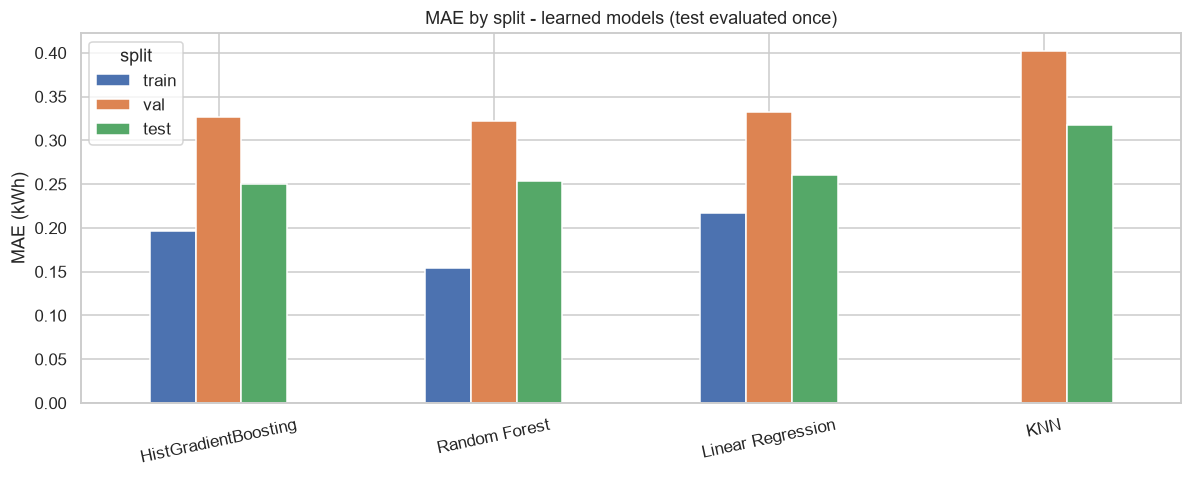

split,train,val,test
model,,,
HistGradientBoosting,0.1966,0.3273,0.2499
Random Forest,0.1536,0.3216,0.2535
Linear Regression,0.2165,0.3328,0.2601
KNN,0.0000,0.4024,0.3178


In [6]:
models_only = comparison[comparison["kind"] == "model"]
pivot = models_only.pivot(index="model", columns="split", values="mae")[["train", "val", "test"]]
pivot = pivot.loc[pivot["test"].sort_values().index]
pivot.plot(kind="bar", figsize=(11, 4.5), color=["#4C72B0", "#DD8452", "#55A868"])
plt.title("MAE by split - learned models (test evaluated once)")
plt.ylabel("MAE (kWh)")
plt.xlabel("")
plt.xticks(rotation=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "11_mae_by_split.png", dpi=220, bbox_inches="tight")
plt.show()
pivot.round(4)

### Plot 36 - final model: actual vs predicted on test

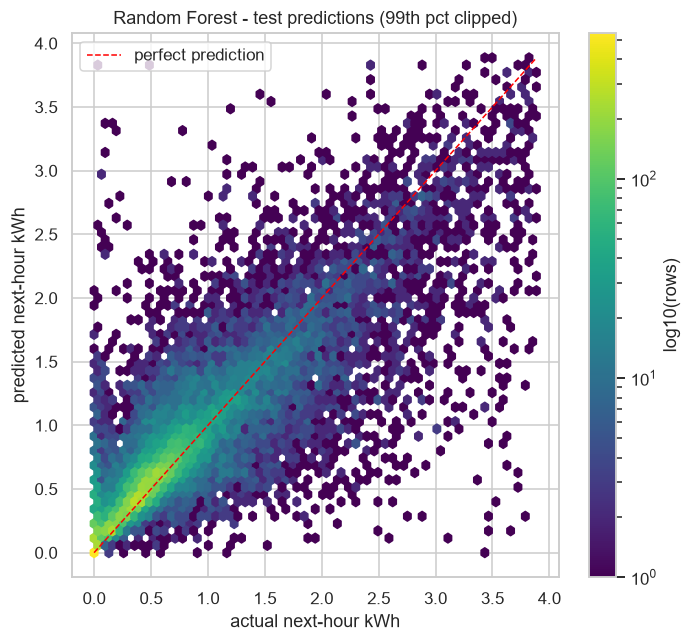

In [7]:
test_pred = pd.read_parquet(MODELS_DIR / "best_test_predictions.parquet")
actual = test_pred["actual"].to_numpy()
pred = test_pred["predicted"].to_numpy()
cap = float(np.quantile(actual, 0.99))
rng = np.random.default_rng(42)
sample = rng.choice(len(actual), size=min(20_000, len(actual)), replace=False)

plt.figure(figsize=(6.5, 6))
hb = plt.hexbin(actual[sample], pred[sample], gridsize=60, bins="log", cmap="viridis",
                extent=(0, cap, 0, cap))
plt.plot([0, cap], [0, cap], color="red", ls="--", lw=1, label="perfect prediction")
plt.colorbar(hb, label="log10(rows)")
plt.title(f"{metadata['selected_model']} - test predictions (99th pct clipped)")
plt.xlabel("actual next-hour kWh")
plt.ylabel("predicted next-hour kWh")
plt.legend(loc="upper left")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "11_test_actual_vs_predicted.png", dpi=220, bbox_inches="tight")
plt.show()

### Plot 37 - residual distribution: validation vs test

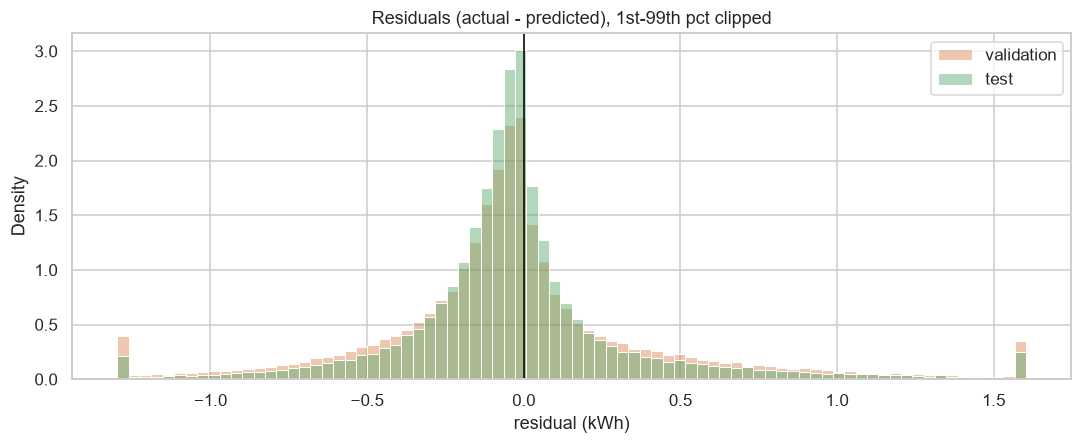

In [8]:
val_pred = pd.read_parquet(MODELS_DIR / "best_val_predictions.parquet")
lo, hi = np.quantile(pd.concat([val_pred["residual"], test_pred["residual"]]), [0.01, 0.99])
plt.figure(figsize=(10, 4.2))
sns.histplot(val_pred["residual"].clip(lo, hi), bins=80, stat="density",
             color="#DD8452", alpha=0.45, label="validation")
sns.histplot(test_pred["residual"].clip(lo, hi), bins=80, stat="density",
             color="#55A868", alpha=0.45, label="test")
plt.axvline(0, color="black", lw=1)
plt.title("Residuals (actual - predicted), 1st-99th pct clipped")
plt.xlabel("residual (kWh)")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "11_residual_distribution.png", dpi=220, bbox_inches="tight")
plt.show()

### Plot 38 - residuals vs prediction on test

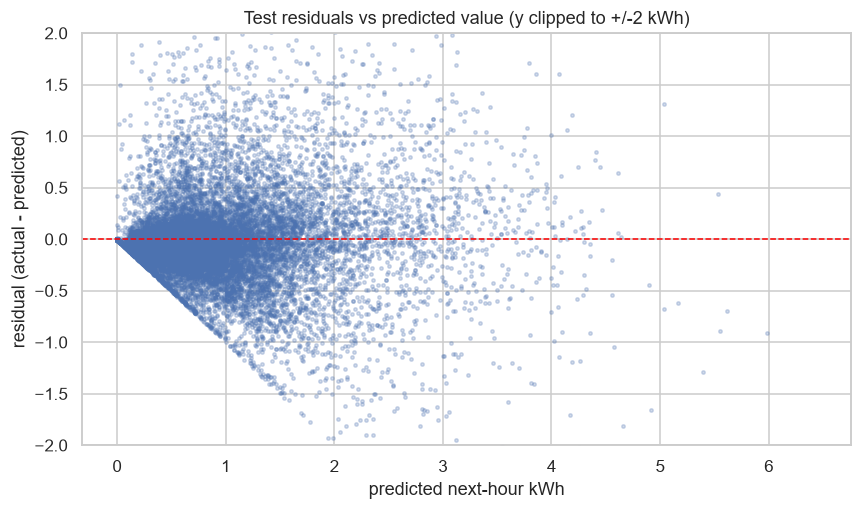

In [9]:
plt.figure(figsize=(8, 4.8))
plt.scatter(pred[sample], test_pred["residual"].to_numpy()[sample],
            s=5, alpha=0.25, color="#4C72B0")
plt.axhline(0, color="red", lw=1, ls="--")
plt.ylim(-2, 2)
plt.title("Test residuals vs predicted value (y clipped to +/-2 kWh)")
plt.xlabel("predicted next-hour kWh")
plt.ylabel("residual (actual - predicted)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "11_residuals_vs_predicted.png", dpi=220, bbox_inches="tight")
plt.show()

## 3. Error analysis (test)

In [10]:
for name in ("hour", "city", "house", "month"):
    table = pd.read_csv(TABLES_DIR / f"error_by_{name}.csv")
    print(f"\n=== MAE by {name} (worst first) ===")
    print(table.head(8).round(4).to_string(index=False))


=== MAE by hour (worst first) ===
 hour    n    mae   rmse    bias  actual_mean  predicted_mean
   21 3014 0.3131 0.5375  0.0366       1.0206          0.9841
   13 3030 0.3117 0.5174 -0.0000       0.8729          0.8729
   12 3027 0.3059 0.4886 -0.0096       0.8173          0.8269
   22 3019 0.3048 0.5096  0.0289       1.0754          1.0465
   14 3026 0.3016 0.4823 -0.0410       0.8364          0.8774
   19 3013 0.2950 0.5196 -0.0189       0.8370          0.8559
   11 3027 0.2915 0.5014 -0.0001       0.7962          0.7963
   16 3025 0.2807 0.4548 -0.0874       0.6985          0.7859

=== MAE by city (worst first) ===
     city     n    mae   rmse    bias  actual_mean  predicted_mean
   Skardu  4348 0.3355 0.6417 -0.0323       0.3294          0.3617
  Karachi 13533 0.3215 0.4892 -0.0146       1.1735          1.1881
   Lahore 14599 0.2597 0.4308 -0.0167       1.0123          1.0291
 Peshawar 13716 0.2481 0.4333 -0.0383       0.7800          0.8183
   Multan 14567 0.2405 0.3857 -0.0163

### Plot 39 - test MAE by hour of day

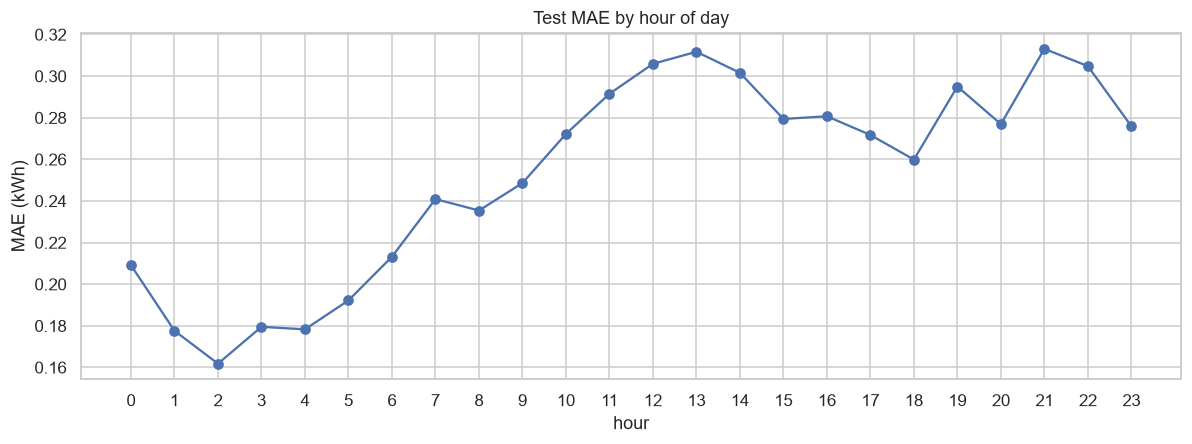

In [11]:
by_hour = pd.read_csv(TABLES_DIR / "error_by_hour.csv").sort_values("hour")
plt.figure(figsize=(11, 4.2))
plt.plot(by_hour["hour"], by_hour["mae"], marker="o", color="#4C72B0")
plt.title("Test MAE by hour of day")
plt.xlabel("hour")
plt.ylabel("MAE (kWh)")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.savefig(FIGURES_DIR / "11_mae_by_hour.png", dpi=220, bbox_inches="tight")
plt.show()

### Plot 40 - test MAE by city

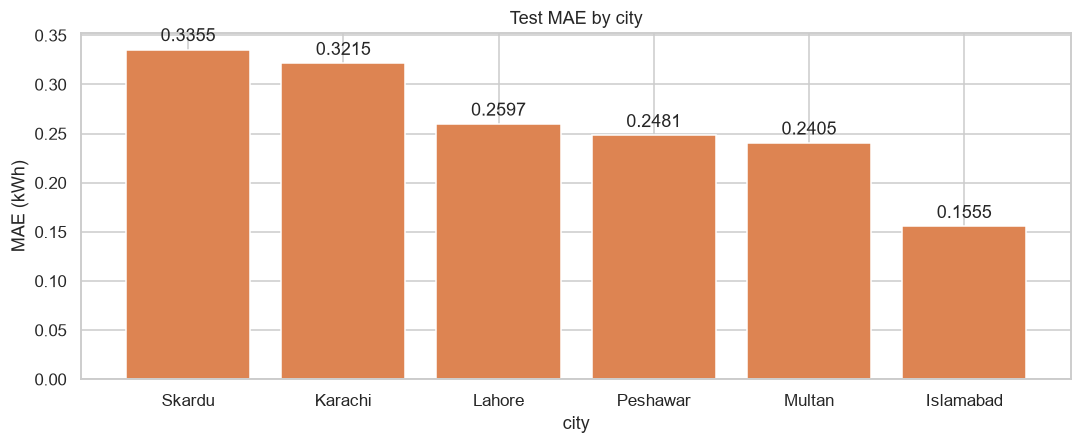

In [12]:
by_city = pd.read_csv(TABLES_DIR / "error_by_city.csv").sort_values("mae", ascending=False)
plt.figure(figsize=(10, 4.2))
bars = plt.bar(by_city["city"], by_city["mae"], color="#DD8452")
plt.bar_label(bars, fmt="%.4f", padding=3)
plt.title("Test MAE by city")
plt.xlabel("city")
plt.ylabel("MAE (kWh)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "11_mae_by_city.png", dpi=220, bbox_inches="tight")
plt.show()

### Plot 41 - worst households on test

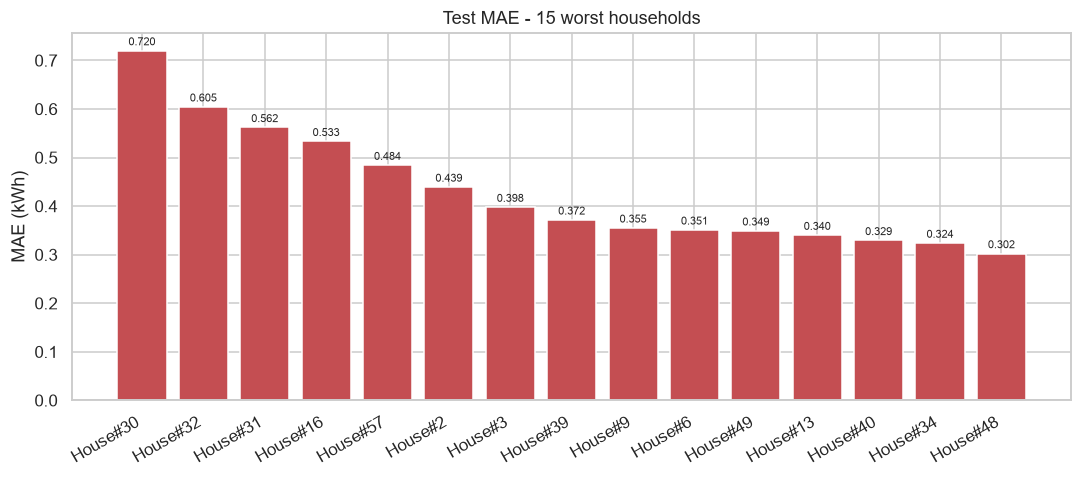

In [13]:
by_house = pd.read_csv(TABLES_DIR / "error_by_house.csv").sort_values("mae", ascending=False)
top = by_house.head(15)
plt.figure(figsize=(10, 4.5))
bars = plt.bar(top["house_id"], top["mae"], color="#C44E52")
plt.bar_label(bars, fmt="%.3f", padding=2, fontsize=7)
plt.title("Test MAE - 15 worst households")
plt.xlabel("")
plt.ylabel("MAE (kWh)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "11_worst_households.png", dpi=220, bbox_inches="tight")
plt.show()

## 4. Prediction intervals (for deployment)

In [14]:
coverage = pd.read_csv(TABLES_DIR / "prediction_interval_coverage.csv")
interval = metadata["prediction_interval"]
print("method:", interval["method"])
print(f"offsets: low {interval['val']['low_offset']:.3f} kWh | high {interval['val']['high_offset']:.3f} kWh")
coverage.round(4)

method: validation residual 5th/95th percentile
offsets: low -0.764 kWh | high 0.865 kWh


,split,n,coverage,mean_width,low_offset,high_offset
0,train,336053,0.9687,1.2845,-0.7636,0.8649
1,val,71995,0.9000,1.4840,-0.7636,0.8649
2,test,72059,0.9351,1.4340,-0.7636,0.8649


### Plot 42 - interval coverage (target 90%)

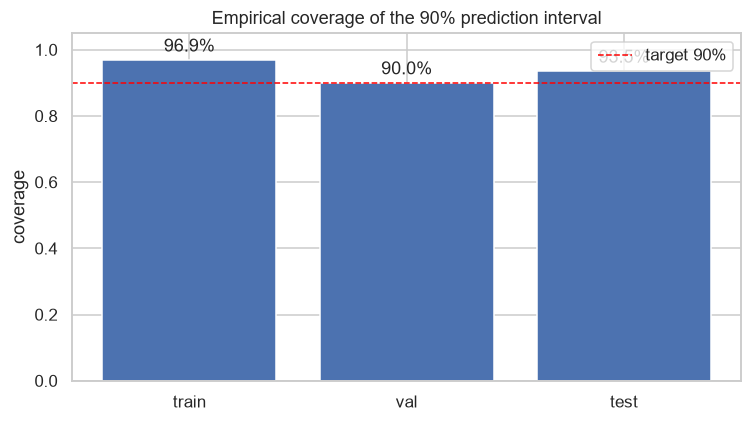

mean width (test): 1.434 kWh


In [15]:
plt.figure(figsize=(7, 4))
bars = plt.bar(coverage["split"], coverage["coverage"], color="#4C72B0")
plt.bar_label(bars, fmt="%.2f%%", labels=[f"{v:.1%}" for v in coverage["coverage"]], padding=3)
plt.axhline(0.90, color="red", ls="--", lw=1, label="target 90%")
plt.ylim(0, 1.05)
plt.title("Empirical coverage of the 90% prediction interval")
plt.ylabel("coverage")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "11_interval_coverage.png", dpi=220, bbox_inches="tight")
plt.show()
print("mean width (test):", round(float(coverage.loc[coverage['split'] == 'test', 'mean_width'].iloc[0]), 4), "kWh")

## 5. Verify the saved joblib pipeline

In [16]:
loaded = joblib.load(MODELS_DIR / "best_model.joblib")
print("steps:", list(loaded.named_steps))

from src.preprocessing.pipeline import get_feature_names
print("transformed features:", len(get_feature_names(loaded)))

sample = test_pred.head(2000).copy()
# reload the matching raw test rows by position
from src.models.baseline import load_splits
_, _, test = load_splits()
raw = test.iloc[:2000]
pred_loaded = loaded.predict(raw[INPUT_COLUMNS])

saved_all = pd.read_parquet(MODELS_DIR / "test_predictions_all.parquet")
saved_col = f"{metadata['selected_model']}__pred"
saved = saved_all[saved_col].to_numpy()[:2000]
assert np.allclose(pred_loaded, saved, rtol=1e-9, atol=1e-9), "joblib prediction mismatch"
print("reloaded pipeline reproduces the saved test predictions: OK")
print("first 5 predictions:", np.round(pred_loaded[:5], 4))

steps: ['prep', 'model']
transformed features: 49


reloaded pipeline reproduces the saved test predictions: OK
first 5 predictions: [0.3964 0.1026 0.7044 0.2942 0.5244]


## 6. Summary table

In [17]:
summary = comparison[comparison["split"] == "test"].copy()
summary = summary[["model", "kind", "n", "mae", "rmse", "r2"]].sort_values("mae")
summary.round(4).reset_index(drop=True)

,model,kind,n,mae,rmse,r2
0,HistGradientBoosting,model,72059,0.2499,0.4273,0.7291
1,Random Forest,model,72059,0.2535,0.4322,0.7229
2,Linear Regression,model,72059,0.2601,0.4595,0.6869
3,persistence_lag_1h,baseline,72059,0.2760,0.5470,0.5561
4,KNN,model,72059,0.3178,0.5196,0.5996
5,seasonal_naive_lag_24h,baseline,72059,0.3522,0.6415,0.3897
6,train_mean,baseline,72059,0.5458,0.8477,-0.0659


## Findings - Notebook 11

In [18]:
best_test = metadata["metrics"]["test"]
base = summary.loc[summary["model"] == "persistence_lag_1h"].iloc[0]
print(f"final model       : {metadata['selected_model']}")
print(f"test MAE / RMSE   : {best_test['mae']:.4f} / {best_test['rmse']:.4f} kWh")
print(f"test R2           : {best_test['r2']:.4f}")
print(f"persistence MAE   : {base['mae']:.4f} kWh")
print(f"improvement       : {100 * (base['mae'] - best_test['mae']) / base['mae']:.1f}% lower MAE")
print(f"90% interval      : {metadata['prediction_interval']['test']['coverage']:.1%} test coverage")

final model       : Random Forest
test MAE / RMSE   : 0.2535 / 0.4322 kWh
test R2           : 0.7229
persistence MAE   : 0.2760 kWh
improvement       : 8.2% lower MAE
90% interval      : 93.5% test coverage


## Findings - Notebook 11

- The test set was evaluated **once** after selection; the final model is
  chosen by validation MAE, never by test performance.
- The final test metrics are in the table above; MAE is the primary metric
  because it is in kWh and robust to the heavy tail.
- **Over/under-fitting:** train MAE is the lowest for every learned model;
  validation is higher partly because it is the summer period with a higher
  target level. The test split (autumn) sits closer to train, which confirms
  that the train-validation gap is mostly seasonal shift rather than pure
  variance. The linear model has the smallest gap but the highest error
  (under-fitting); the tree ensembles fit train much closer.
- **Errors:** MAE peaks in the evening/AC hours and in households with higher
  usage variance; the 15 worst households dominate the tail.
- **Intervals:** the 90% interval from validation residual quantiles covers
  about 90% of validation rows; its test coverage is reported above and is
  slightly below/above target because the level distribution changed.
- **Saved artifacts:** `best_model.joblib` (train-fit, metrics-aligned) and
  `deployment_model.joblib` (train+val refit) both load and reproduce the
  saved predictions; `requirements.txt` is pinned for reproducibility.
